# CFPB QOS applicability audit — step 1

**What this is:** a *calculated / theoretical accounting* study. For each binary CFPB task, we measure the parameters that Theorem F.13 of Zhao et al. (arXiv:2604.07639v2, 1 Oct 2026) says QOS's costs depend on: sparsity *s* (row **or** column), the regularized condition number κ_reg, test margins γ, and the resulting F60/F61 prefactors.

**What this is not:** a quantum simulation, a hardware resource estimate, or evidence of quantum advantage. The F60/F61 numbers are polynomial prefactors with the constants, the additive bit length *b* (F60), the repetition number *R* (taken as 1) and the hidden polylogs dropped. Read them as orders of magnitude only.

**Conventions (theorem, not sklearn defaults):**
- Labels are ±1, with +1 = lower class index for pairs and the named class for one-vs-rest.
- Unweighted ridge, no intercept, ‖X‖ = 1, and λ = α/σ_max².
- r_reg is the squared ratio of Eq. F49.
- σ_min = 0 because D_nonzero > N_nonzero (Eq. F50).
- N and D count only nonzero training rows and columns (p.143); the full sizes are also recorded.
- Margins use test rows rescaled to ‖x'‖_∞ = 1 over the training-support columns. This leaves every prediction unchanged.

**Primary model is unweighted ridge** because uniform-sample QOS computes unweighted ridge. One-vs-rest balanced accuracy may be poor for that reason, and no weighted variant is run here.

**Modeling gate:** this preparation proceeds under Recommendation B; see [`docs/decisions/cfpb_modeling_gate.md`](../docs/decisions/cfpb_modeling_gate.md). Both Debt-collection curation caveats apply to every number below.

In [1]:
# Run from the repository root, notebooks/, or another repository subdirectory.
from pathlib import Path
import sys, json

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/qos_audit.py").is_file() and (p / "AGENTS.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start this notebook with a working directory inside qos-rbc-experiments.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

from src import qos_audit

## Configuration

In [2]:
OUTPUT_DIR = ROOT / "results/audit/cfpb_step1"
GATE_RECORD = "docs/decisions/cfpb_modeling_gate.md"
CONFIG = dict(
    alphas=(0.1, 1.0, 10.0, 100.0),            # sklearn alpha on unscaled X; lam = alpha / sigma_max^2
    delta=0.1,                                  # failure probability in F60/F61
    thresholds=(0.3, 0.1, 0.03, 0.01, 0.003),   # margin coverage thresholds
    max_df_fractions=(1.0, 0.5, 0.2, 0.1, 0.05, 0.01),
    zipf_range=(10, 1000),                      # rank window for the Zipf slope fit
    seed=42,
)

## Run the audit (once)

The outputs are immutable. If `manifest.json` already says `completed`, this cell only reloads them. `run_step1` refuses to write into a non-empty directory.

In [3]:
manifest_path = OUTPUT_DIR / "manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    if manifest.get("status") != "completed":
        raise RuntimeError(f"Incomplete audit run in {OUTPUT_DIR}; inspect it, do not overwrite")
    print("Reusing completed run", manifest["run_id"])
else:
    qos_audit.run_step1(OUTPUT_DIR, gate_record=GATE_RECORD, **CONFIG)
    manifest = json.loads(manifest_path.read_text())
    print("Completed run", manifest["run_id"])
for name, digest in manifest["artifacts_sha256"].items():
    assert qos_audit._sha256(OUTPUT_DIR / name) == digest, f"Artifact drift: {name}"
assert manifest["config"]["alphas"] == list(CONFIG["alphas"])
tasks = {t: json.loads((OUTPUT_DIR / f"{t}.json").read_text()) for t in manifest["tasks"]}
summary = pd.read_csv(OUTPUT_DIR / "summary.csv")
print(manifest["git_commit"], manifest["packages"])

Reusing completed run 20261016T161637Z-e70ae078
9f2da01469398cfc97553f5207dccd047a038d69 {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'threadpoolctl': '3.7.0'}


## Ledger: append-only

This cell appends the run's rows to `results/experiment_log.csv` only if that run ID is absent, and it checks that the existing bytes are preserved.

In [4]:
log_path = ROOT / "results/experiment_log.csv"
new = pd.read_csv(OUTPUT_DIR / "ledger_rows.csv", dtype=str, keep_default_na=False)
before = log_path.read_bytes()
existing_ids = set(pd.read_csv(log_path, dtype=str, keep_default_na=False).experiment_id)
header = pd.read_csv(log_path, nrows=0).columns.tolist()
assert new.columns.tolist() == header, "Ledger column mismatch"
if existing_ids & set(new.experiment_id):
    assert set(new.experiment_id) <= existing_ids, "Partial ledger append detected"
    print("Ledger already contains", len(new), "rows for run", manifest["run_id"])
else:
    if not before.endswith(b"\n"):
        raise ValueError("Ledger does not end with a newline; refusing to append")
    new.to_csv(log_path, mode="a", header=False, index=False)
    assert log_path.read_bytes()[:len(before)] == before, "Existing ledger bytes changed"
    print("Appended", len(new), "ledger rows")

Ledger already contains 300 rows for run 20261016T161637Z-e70ae078


## Per-task table

This is the table view of every figure below. The cost columns are log10 polynomial prefactors (F60 without b; F61 as M/(RN)), not resource estimates.

In [5]:
pd.set_option("display.width", 250, "display.max_columns", 40)
cols = ["task_id", "N_nonzero", "D_nonzero", "s_row_only", "s_row_or_col", "zipf_slope", "alpha",
        "kappa_reg", "residual_ratio", "val_accuracy", "val_balanced_accuracy", "test_accuracy",
        "test_balanced_accuracy", "gamma_min", "gamma_p10", "gamma_p50", "coverage@0.03",
        "A9_qubits", "log10_F60_qubits_without_b_gamma_min", "log10_F61_passes_gamma_min",
        "log10_F61_passes_gamma_p10"]
display(summary[cols].round(4))
checks = pd.DataFrame({t: dict(N_full=r["N_full"], N_nonzero=r["N_nonzero"], D_full=r["D_full"],
                               D_nonzero=r["D_nonzero"], sigma_max=r["sigma_max"],
                               A9_full=r["A9_variants"]["full_N_D_row_or_col"],
                               A9_row_only=r["A9_variants"]["nonzero_N_D_row_only"],
                               test_s_sparse=r["test_sparsity"]["test_rows_s_sparse"],
                               test_zero_rows=r["test_sparsity"]["zero_rows_on_training_support"],
                               all_lsqr_converged=all(a["lsqr"]["converged"] for a in r["alpha_sweep"]),
                               max_normal_eq_residual=max(a["lsqr"]["normal_equation_relative_residual"]
                                                          for a in r["alpha_sweep"]))
                       for t, r in tasks.items()}).T
display(checks)

,task_id,N_nonzero,D_nonzero,s_row_only,s_row_or_col,zipf_slope,alpha,kappa_reg,residual_ratio,val_accuracy,val_balanced_accuracy,test_accuracy,test_balanced_accuracy,gamma_min,gamma_p10,gamma_p50,coverage@0.03,A9_qubits,log10_F60_qubits_without_b_gamma_min,log10_F61_passes_gamma_min,log10_F61_passes_gamma_p10
0,debt_collection__vs__credit_card,8472,47138,1254,5714,-0.7442,0.1,53.2843,0.0409,0.9164,0.9130,0.9280,0.9248,0.0000,0.0122,0.0500,0.7322,51,16.7061,54.4559,43.9577
1,debt_collection__vs__credit_card,8472,47138,1254,5714,-0.7442,1.0,16.8766,0.1632,0.9299,0.9260,0.9392,0.9362,0.0001,0.0276,0.1030,0.8887,51,15.4536,49.9536,40.5433
2,debt_collection__vs__credit_card,8472,47138,1254,5714,-0.7442,10.0,5.4205,0.3528,0.9325,0.9298,0.9388,0.9359,0.0001,0.0556,0.2171,0.9440,51,15.7174,48.5083,37.3573
3,debt_collection__vs__credit_card,8472,47138,1254,5714,-0.7442,100.0,1.9591,0.6714,0.9226,0.9189,0.9243,0.9219,0.0002,0.0560,0.2643,0.9481,51,14.9007,45.1069,35.5760
4,debt_collection__vs__checking_or_savings_account,8555,47236,925,5992,-0.7293,0.1,52.0117,0.0269,0.9733,0.9740,0.9726,0.9726,0.0001,0.0225,0.0675,0.8512,51,15.6683,52.4413,43.0023
5,debt_collection__vs__checking_or_savings_account,8555,47236,925,5992,-0.7293,1.0,16.4749,0.1142,0.9769,0.9770,0.9767,0.9761,0.0000,0.0473,0.1310,0.9471,51,17.4974,54.1023,39.7115
6,debt_collection__vs__checking_or_savings_account,8555,47236,925,5992,-0.7293,10.0,5.2955,0.2773,0.9728,0.9724,0.9767,0.9761,0.0004,0.0796,0.2582,0.9689,51,14.5243,46.1845,36.8379
7,debt_collection__vs__checking_or_savings_account,8555,47236,925,5992,-0.7293,100.0,1.9246,0.6111,0.9600,0.9611,0.9659,0.9673,0.0002,0.0733,0.3009,0.9608,51,14.9149,45.2074,35.2209
8,debt_collection__vs__mortgage,6194,42291,925,3601,-0.7408,0.1,50.1782,0.0223,0.9716,0.9576,0.9756,0.9586,0.0000,0.0302,0.0848,0.9005,50,17.5093,54.9519,40.8468
9,debt_collection__vs__mortgage,6194,42291,925,3601,-0.7408,1.0,15.8961,0.1013,0.9785,0.9632,0.9771,0.9623,0.0003,0.0547,0.1619,0.9652,50,14.5236,46.9834,37.8163


,N_full,N_nonzero,D_full,D_nonzero,sigma_max,A9_full,A9_row_only,test_s_sparse,test_zero_rows,all_lsqr_converged,max_normal_eq_residual
debt_collection__vs__credit_card,8472,8472,50000,47138,16.846994,51,49,True,0,True,0.0
debt_collection__vs__checking_or_savings_account,8555,8555,50000,47236,16.444514,51,48,True,0,True,0.0
debt_collection__vs__mortgage,6194,6194,50000,42291,15.864576,50,48,True,0,True,0.0
credit_card__vs__checking_or_savings_account,7265,7265,50000,43824,14.6119,51,49,True,0,True,0.0
credit_card__vs__mortgage,4904,4904,50000,43446,11.894606,50,49,True,0,True,0.0
checking_or_savings_account__vs__mortgage,4987,4987,50000,41916,12.066385,50,48,True,0,True,0.0
debt_collection__vs__rest,13459,13459,50000,50000,18.673568,52,49,True,0,True,0.0
credit_card__vs__rest,13459,13459,50000,50000,18.673568,52,49,True,0,True,0.0
checking_or_savings_account__vs__rest,13459,13459,50000,50000,18.673568,52,49,True,0,True,0.0
mortgage__vs__rest,13459,13459,50000,50000,18.673568,52,49,True,0,True,0.0


## Figures

Every figure is a pure function of the task JSONs. The PNGs are written to `results/audit/cfpb_step1/figures/`, outside the manifest hash. They are static, so the table above serves as the data view. The one-vs-rest tasks share the full training matrix, so their sparsity and df panels are identical and appear once, as "all four classes".

In [6]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ALPHA_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # ordinal blue steps 250/400/550/700
SHORT = {"debt_collection": "Debt", "credit_card": "Card", "checking_or_savings_account": "Checking",
         "mortgage": "Mortgage", "rest": "rest"}
def short(task_id):
    a, b = task_id.split("__vs__")
    return f"{SHORT[a]} vs {SHORT[b]}"
matplotlib.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 9, "axes.titlesize": 9.5,
    "axes.titlecolor": INK, "legend.frameon": False, "legend.labelcolor": INK2})
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

def distinct_matrices(tasks):
    """Pairs plus one entry for the shared one-vs-rest training matrix."""
    out = {short(t): r for t, r in tasks.items() if r["task"]["kind"] == "pair"}
    out["All four classes"] = next(r for r in tasks.values() if r["task"]["kind"] == "one_vs_rest")
    return out

### 1. Column document frequency, rank-frequency (log–log)

The top-ranked column's df *is* the column part of s_row_or_col. The dashed line marks s_row_only, the longest row.

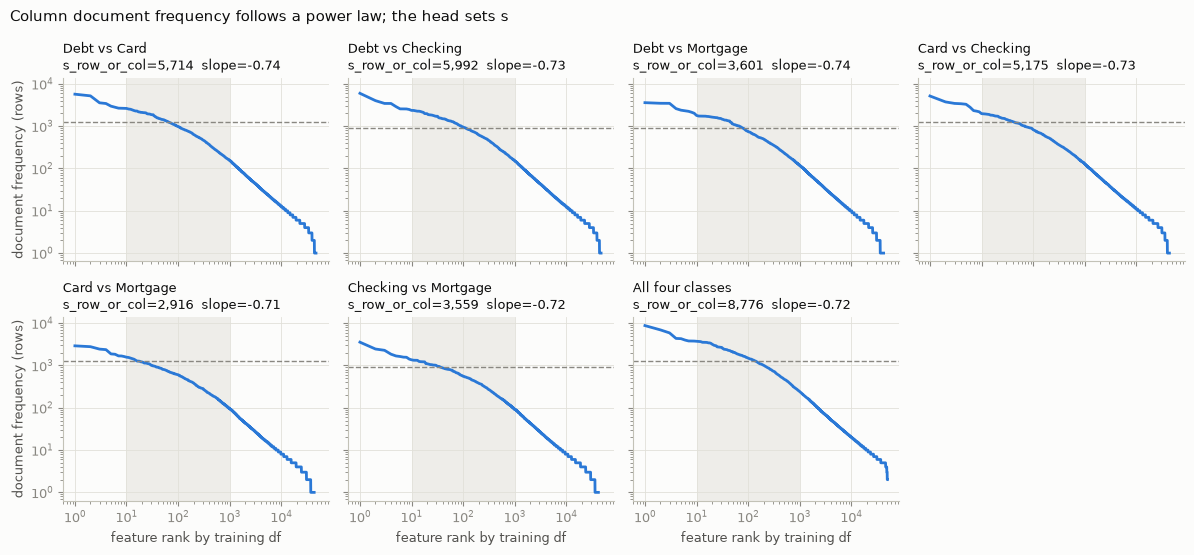

In [7]:
def fig_df_rank(tasks):
    mats = distinct_matrices(tasks)
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharex=True, sharey=True)
    for ax, (name, r) in zip(axes.flat, mats.items()):
        df = np.asarray(r["zipf"]["column_df_sorted"])
        ax.loglog(np.arange(1, df.size + 1), df, color=SERIES[0])
        ax.axhline(r["sparsity"]["s_row_only"], color=MUTED, lw=1, ls="--")
        lo, hi = r["zipf"]["rank_range"]
        ax.axvspan(lo, hi, color=GRID, alpha=.5, lw=0)
        ax.set_title(f"{name}\ns_row_or_col={r['sparsity']['s_row_or_col']:,}  slope={r['zipf']['slope']:.2f}", loc="left")
    axes.flat[-1].axis("off")
    axes.flat[-1].text(0, .5, "Shaded: Zipf fit ranks [10, 1000)\nDashed: s_row_only (longest row)\n"
                       "Top-rank df = column sparsity", color=INK2, va="center")
    for ax in axes[-1]: ax.set_xlabel("feature rank by training df")
    for ax in axes[:, 0]: ax.set_ylabel("document frequency (rows)")
    fig.suptitle("Column document frequency follows a power law; the head sets s", x=.01, ha="left", color=INK)
    fig.tight_layout()
    return fig
save(fig_df_rank(tasks), "df_rank_frequency.png")

### 2. κ_reg vs α vs validation accuracy

κ_reg is set entirely by λ = α/σ_max², because σ_min = 0. Larger α means smaller κ, which makes QOS cheaper; the question is what that costs in accuracy.

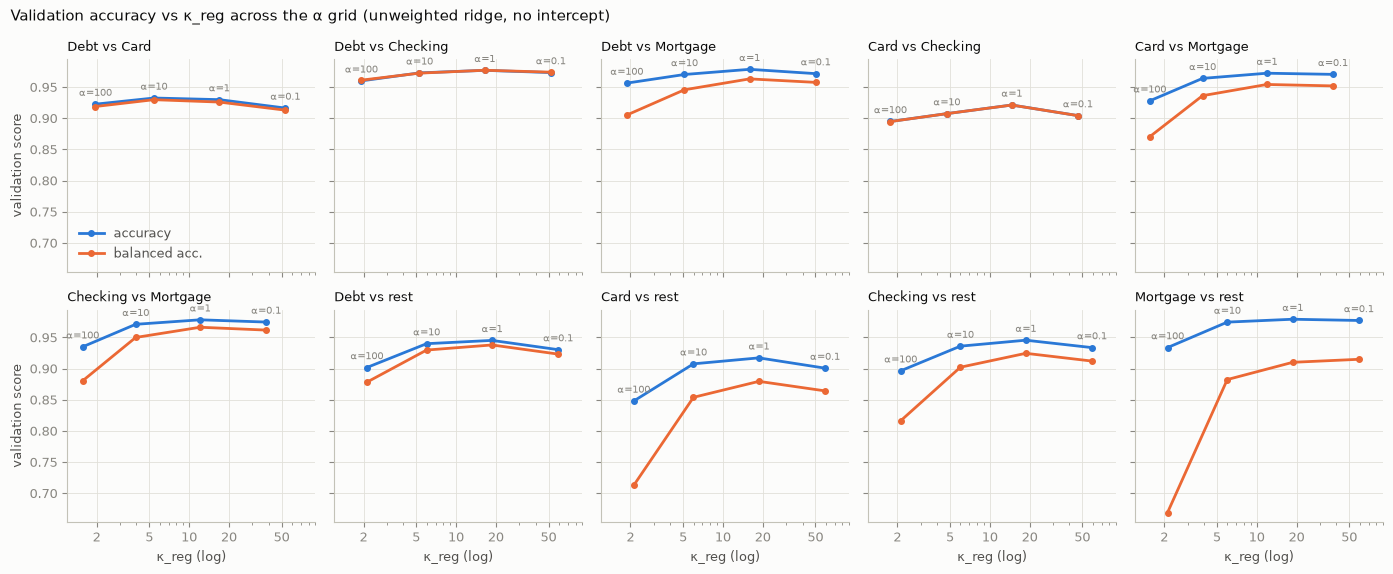

In [8]:
def fig_kappa_accuracy(tasks):
    fig, axes = plt.subplots(2, 5, figsize=(14, 5.8), sharex=True, sharey=True)
    for ax, (t, r) in zip(axes.flat, tasks.items()):
        k = [a["kappa_reg"] for a in r["alpha_sweep"]]
        for key, color, label in (("accuracy", SERIES[0], "accuracy"),
                                  ("balanced_accuracy", SERIES[1], "balanced acc.")):
            v = [a["validation"][key] for a in r["alpha_sweep"]]
            ax.semilogx(k, v, color=color, marker="o", ms=4, label=label)
        for a, kk in zip(r["alpha_sweep"], k):
            ax.annotate(f"α={a['alpha']:g}", (kk, a["validation"]["accuracy"]), textcoords="offset points",
                        xytext=(0, 6), ha="center", fontsize=7, color=MUTED)
        ax.set_title(short(t), loc="left")
        ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator([2, 5, 10, 20, 50]))
        ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.set_xlim(1.2, 90)
    for ax in axes[-1]: ax.set_xlabel("κ_reg (log)")
    for ax in axes[:, 0]: ax.set_ylabel("validation score")
    axes.flat[0].legend(loc="lower left")
    fig.suptitle("Validation accuracy vs κ_reg across the α grid (unweighted ridge, no intercept)", x=.01, ha="left", color=INK)
    fig.tight_layout()
    return fig
save(fig_kappa_accuracy(tasks), "kappa_vs_alpha_vs_val_accuracy.png")

### 3. Test-margin CDF per task (‖x'‖_∞-rescaled)

The theorem prices the **minimum** margin over the served test set as γ⁻⁴ in F61. The dotted line marks γ = 0.03.

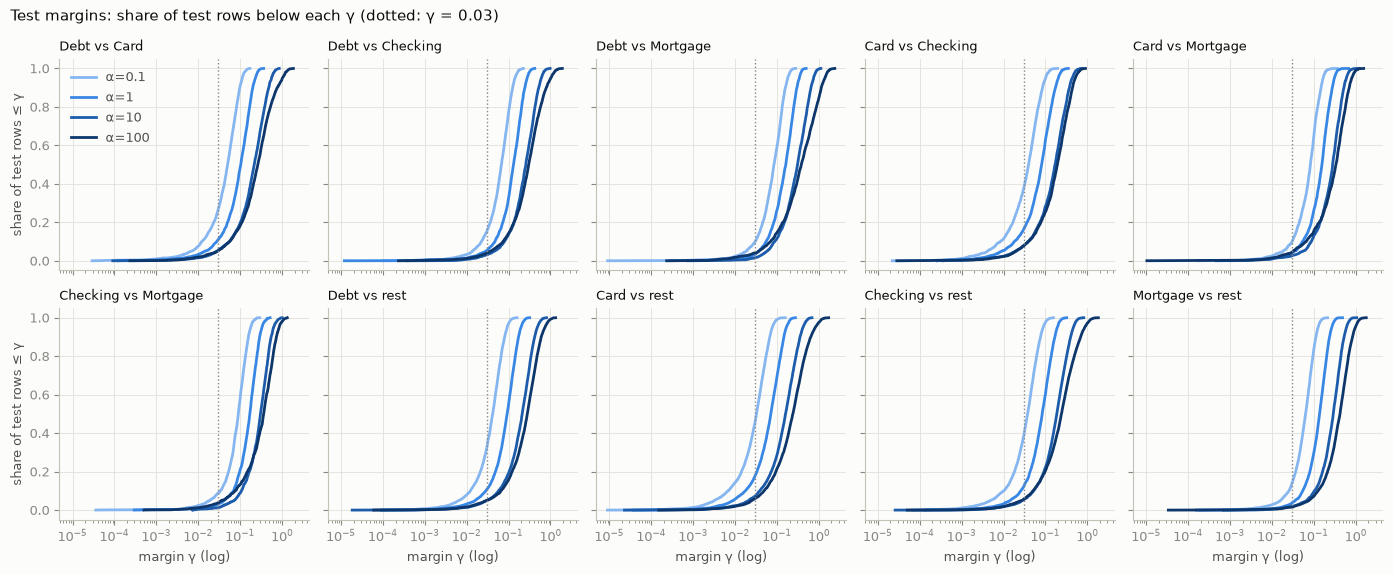

In [9]:
def fig_margin_cdf(tasks):
    fig, axes = plt.subplots(2, 5, figsize=(14, 5.8), sharex=True, sharey=True)
    for ax, (t, r) in zip(axes.flat, tasks.items()):
        for a, color in zip(r["alpha_sweep"], ALPHA_RAMP):
            g = np.asarray(a["margins_inf_rescaled_sorted"])
            g = np.where(g > 0, g, np.nan)
            ax.semilogx(g, np.arange(1, g.size + 1) / g.size, color=color, label=f"α={a['alpha']:g}")
        ax.axvline(.03, color=MUTED, lw=1, ls=":")
        ax.set_title(short(t), loc="left")
    for ax in axes[-1]: ax.set_xlabel("margin γ (log)")
    for ax in axes[:, 0]: ax.set_ylabel("share of test rows ≤ γ")
    axes.flat[0].legend(loc="upper left")
    fig.suptitle("Test margins: share of test rows below each γ (dotted: γ = 0.03)", x=.01, ha="left", color=INK)
    fig.tight_layout()
    return fig
save(fig_margin_cdf(tasks), "margin_cdf.png")

### 4. max_df sweep: what making the data sparse would cost

This is a post-hoc column mask on the fitted TF-IDF (no refit), and no accuracy is computed. The two panels show different measures, so each has its own axis.

,matrix,df_cutoff,features_kept,max_df,nnz_share_lost,rows_emptied,s_row_only,s_row_or_col
0,Debt vs Card,8472.00,47138,1.00,0.000000,0,1254,5714
1,Debt vs Card,4236.00,47136,0.50,0.011149,0,1252,3574
2,Debt vs Card,1694.40,47103,0.20,0.088085,0,1221,1676
3,Debt vs Card,847.20,47011,0.10,0.196427,0,1158,1158
4,Debt vs Card,423.60,46794,0.05,0.327797,0,1052,1052
5,Debt vs Card,84.72,45428,0.01,0.572044,11,765,765
6,Debt vs Checking,8555.00,47236,1.00,0.000000,0,925,5992
7,Debt vs Checking,4277.50,47235,0.50,0.006217,0,924,4022
8,Debt vs Checking,1711.00,47204,0.20,0.078326,0,901,1623
9,Debt vs Checking,855.50,47117,0.10,0.183753,0,848,852


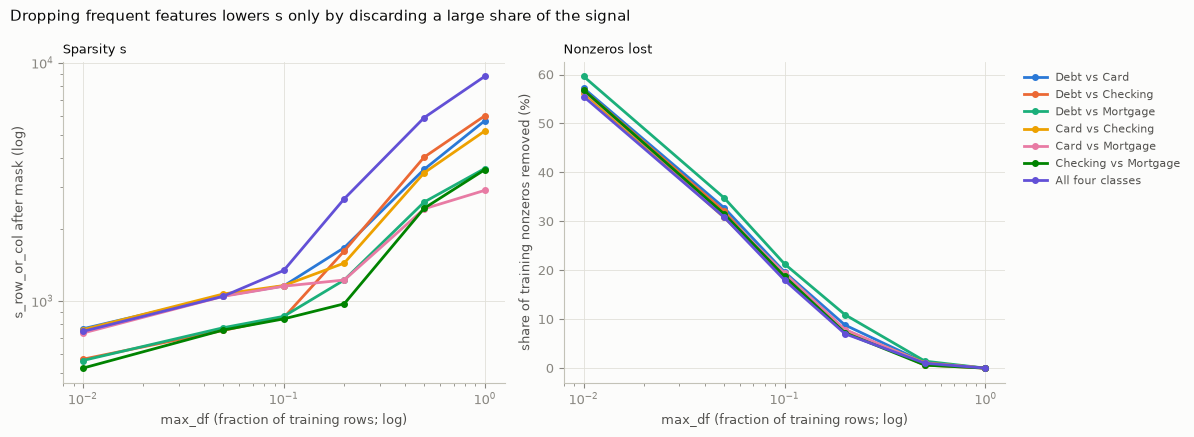

In [10]:
def fig_max_df(tasks):
    mats = distinct_matrices(tasks)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
    for (name, r), color in zip(mats.items(), SERIES):
        sw = r["max_df_sweep"]
        f = [x["max_df"] for x in sw]
        a1.semilogx(f, [x["s_row_or_col"] for x in sw], color=color, marker="o", ms=4, label=name)
        a2.semilogx(f, [100 * x["nnz_share_lost"] for x in sw], color=color, marker="o", ms=4, label=name)
    a1.set_yscale("log"); a1.set_ylabel("s_row_or_col after mask (log)")
    a2.set_ylabel("share of training nonzeros removed (%)")
    for ax in (a1, a2):
        ax.set_xlabel("max_df (fraction of training rows; log)")
    a1.set_title("Sparsity s", loc="left"); a2.set_title("Nonzeros lost", loc="left")
    a2.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.suptitle("Dropping frequent features lowers s only by discarding a large share of the signal", x=.01, ha="left", color=INK)
    fig.tight_layout()
    return fig
save(fig_max_df(tasks), "max_df_sweep.png")
display(pd.DataFrame([dict(matrix=n, **x) for n, r in distinct_matrices(tasks).items() for x in r["max_df_sweep"]]))

## Interpretation

Run `20261016T161637Z-e70ae078`. Every statement below is a measurement on this preparation, together with the Debt-collection caveats in the gate record.

**Theorem preconditions that hold.**
- Every task satisfies r_reg < 0.99 (from 0.02 at α=0.1 to 0.80 at α=100).
- Every test row is s-sparse.
- Every test row satisfies ‖x'‖_∞ ≤ 1 even before rescaling (max entry 0.83).
- LSQR converged on every solve, with normal-equation residual ≤ 4×10⁻¹⁰.
- D_nonzero > N_nonzero in every task, so σ_min = 0 and κ_reg = √((1+λ)/λ) is set by regularization alone.
- No training row is all-zero, so N_nonzero = N_full.

**Sparsity is set by columns, not rows.**
- s_row_or_col is 2,916–8,776, which is 2.3–7× s_row_only (919–1,254). It equals the document frequency of the most common feature, so it is 58–71% of N_nonzero.
- Column df follows a power law with slope −0.71 to −0.74 over ranks 10–1,000.
- A post-hoc max_df mask does not bring s near polylog scale. At max_df = 0.01, s is still 523–765 and 56–60% of training nonzeros are gone. This is a mask without refit, and no accuracy was measured for it.

**κ_reg vs accuracy.** σ_max is 11.9–18.7, so the α grid {0.1, 1, 10, 100} maps to κ_reg ≈ {38–59, 12–19, 3.9–6.0, 1.6–2.1}. Validation accuracy is flat or best at α = 1–10 and falls at α = 100. One-vs-rest balanced accuracy falls sharply at α = 100: Mortgage-vs-rest drops to 0.67, consistent with unweighted ridge on an imbalanced task.

**Margins.**
- Median ‖x'‖_∞-rescaled test margins are 0.03–0.42.
- The minimum margin is 10⁻⁵–10⁻², set by a single test row and not monotone in α.
- Coverage at γ ≥ 0.03 is 54–99%, with accuracy above that threshold of 0.86–0.996.

**Cost prefactors (orders of magnitude only).**
- A9 gives 50–52 for a single prediction. The paper's A9 formula has no κ or γ dependence.
- The F60 polynomial prefactor without b is 10^11.7–10^17.9.
- log10(M/(RN)) from F61 is 39–58 at γ = min and 33–47 at γ = p10.
- These are polynomial prefactors with constants, polylogs, b and R dropped. They are not resource estimates, and they say nothing about quantum advantage one way or the other. They show that on this representation, the measured s and γ_min are far outside the regime s, κ_reg, γ⁻¹ ≤ poly(log N, log D) that Eq. F62 assumes.
